In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
import math 
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/sample_submission.csv
/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/train.csv
/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/test.csv


## Flight Price Prediction
This notebook explores the flight fare dataset, cleans it, engineers features, 
and compares 7 regression models to predict flight ticket prices.

In [2]:
## creating data frame for both train and test data 

df_train = pd.read_csv("/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/train.csv")
df_test = pd.read_csv("/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/test.csv")

# removing the id the very first column 
df_train = df_train.drop(columns = ['id'])

print(f"The shape of Train data is {df_train.shape}")
print(f"The shape of Test data is {df_test.shape}")  # price column not available 
df_train.head(5)   # first 5 data points 

The shape of Train data is (40000, 11)
The shape of Test data is (10000, 11)


,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


### 1. Data Types
Checking the data type of each column to understand which are numerical, 
categorical, and which need conversion.

In [3]:
## datatype of each columns
df_dtypes = pd.DataFrame({"Feature": df_train.columns,
"DataTypes": df_train.dtypes.values})
df_dtypes

,Feature,DataTypes
0,airline,object
1,flight,object
2,source,object
3,departure,object
4,stops,object
5,arrival,object
6,destination,object
7,class,object
8,duration,float64
9,days_left,float64


In [4]:
# information regarding each column 
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   airline      35387 non-null  object 
 1   flight       40000 non-null  object 
 2   source       40000 non-null  object 
 3   departure    35208 non-null  object 
 4   stops        37681 non-null  object 
 5   arrival      40000 non-null  object 
 6   destination  40000 non-null  object 
 7   class        40000 non-null  object 
 8   duration     36987 non-null  float64
 9   days_left    35562 non-null  float64
 10  price        40000 non-null  int64  
dtypes: float64(2), int64(1), object(8)
memory usage: 3.4+ MB


In [5]:
# values in each column excluding float, and int columns 
cols = df_train.columns
except_columns = ['duration', 'days_left', 'price', 'flight']

for col in cols.difference(except_columns):
    print("********************************")
    print(f"{df_train[col].value_counts()}")

********************************
airline
Vistara      15063
Air_India     9222
Indigo        5236
GO_FIRST      2805
AirAsia       1958
SpiceJet      1103
Name: count, dtype: int64
********************************
arrival
Night            12348
Evening          10398
Morning           8340
Afternoon         4989
Early_Morning     2040
Late_Night        1885
Name: count, dtype: int64
********************************
class
Economy     27536
Business    12464
Name: count, dtype: int64
********************************
departure
Morning          8302
Early_Morning    7788
Evening          7709
Night            5690
Afternoon        5565
Late_Night        154
Name: count, dtype: int64
********************************
destination
Mumbai       7821
Delhi        7798
Bangalore    6755
Kolkata      6553
Hyderabad    5689
Chennai      5384
Name: count, dtype: int64
********************************
source
Delhi        8189
Mumbai       8139
Bangalore    6947
Kolkata      6168
Hyderabad    5436
Che

#### **Conclusion**: 

**Feature Types:**
  * **Categorical (8):** `airline`, `flight`, `source`, `departure`, `stops`, `arrival`, `destination`, `class`
  * **Numerical (3):** `duration` (float), `days_left` (float), `price` (int - target)

**Actions:**
  * **Garbage/Corrupted Data:** `flight` contains `0.00E+00` values—drop the `flight` feature entirely as it offers high cardinality without predictive signal.
  * **Missing Value Imputation:** Impute `airline`, `departure`, and `stops` using Mode (most frequent); impute `duration` and `days_left` using Median.
  * **Feature Encoding:** Map `stops` (`zero`→0, `one`→1, `two_or_more`→2) and `class` (`Economy`→0, `Business`→1) via Ordinal Encoding. Apply One-Hot Encoding (`OHE`) to `airline`, `source`, `destination`, `departure`, and `arrival`.
  * **Feature Scaling:** Apply `StandardScaler` to `duration` and `days_left`.

### 2. Descriptive Statistics
Summary statistics (min, max, mean, median) for numerical columns: 
duration, days_left, and price.

In [6]:
## duration
print(f"Median duration {df_train['duration'].median()}")
df_train['duration'].describe()

Median duration 11.08


count    36987.000000
mean        12.004088
std          7.108063
min          0.830000
25%          6.670000
50%         11.080000
75%         15.920000
max         47.080000
Name: duration, dtype: float64

In [7]:
## days_left
print(f"Median Days Left {df_train['days_left'].median()}")
df_train['days_left'].describe()

Median Days Left 26.0


count    35562.000000
mean        26.197936
std         13.469232
min          1.000000
25%         15.000000
50%         26.000000
75%         38.000000
max         49.000000
Name: days_left, dtype: float64

In [8]:
# price (target-column)
print(f"Median Price {df_train['price'].median()}")
df_train['price'].describe()

Median Price 7353.0


count     40000.00000
mean      20801.49025
std       22729.14842
min        1105.00000
25%        4687.00000
50%        7353.00000
75%       42521.00000
max      114704.00000
Name: price, dtype: float64

#### **Conclusion:**

The numerical features show a wide range of values. The average flight duration is about 12 hours, passengers book flights approximately 26 days in advance on average, and ticket prices vary considerably (₹1,105 to ₹114,704), indicating high variability in the target variable.

### 3. Missing Values
Identifying missing values per column and deciding how to handle each — 
drop rows/columns or impute (mean/median for numeric, mode for categorical).

#### df_train Imputing 

In [9]:
# finding all the NA values column wise 
df_train.isnull().sum()

airline        4613
flight            0
source            0
departure      4792
stops          2319
arrival           0
destination       0
class             0
duration       3013
days_left      4438
price             0
dtype: int64

In [10]:
# Filling null values with mode, median on df_train

airline_mode = df_train['airline'].mode()[0]
departure_mode = df_train['departure'].mode()[0]
stops_mode = df_train['stops'].mode()[0]
duration_map = df_train.groupby(['source', 'destination'])['duration'].transform('median')
days_left_median = df_train['days_left'].median()

# airline -> mode, departure -> mode, stops -> mode
df_train['airline'] = df_train['airline'].fillna(airline_mode)
df_train['departure'] = df_train['departure'].fillna(departure_mode)
df_train['stops'] = df_train['stops'].fillna(stops_mode)

# grouped by similar source, destination median duration
df_train['duration'] = df_train['duration'].fillna(duration_map)

# days_left -> median 
df_train['days_left'] = df_train['days_left'].fillna(days_left_median)


df_train.isnull().sum().sum() # No null values left 

np.int64(0)

#### df_test Imputing 

In [11]:
df_test.isnull().sum()

id               0
airline        548
flight           0
source           0
departure      920
stops          651
arrival          0
destination      0
class            0
duration       582
days_left      696
dtype: int64

In [12]:
# Filling null values with mode, median on df_train

airline_mode = df_test['airline'].mode()[0]
departure_mode = df_test['departure'].mode()[0]
stops_mode = df_test['stops'].mode()[0]
duration_map = df_test.groupby(['source', 'destination'])['duration'].transform('median')
days_left_median = df_test['days_left'].median()

# airline -> mode, departure -> mode, stops -> mode
df_test['airline'] = df_test['airline'].fillna(airline_mode)
df_test['departure'] = df_test['departure'].fillna(departure_mode)
df_test['stops'] = df_test['stops'].fillna(stops_mode)

# grouped by similar source, destination median duration
df_test['duration'] = df_test['duration'].fillna(duration_map)

# days_left -> median 
df_test['days_left'] = df_test['days_left'].fillna(days_left_median)


df_test.isnull().sum().sum() # No null values left 

np.int64(0)

#### **Conclusion:**
NaN values make the code algorithmically impossible to solve..
We Imputed uisng mode, median values such that the dataset (both train and test DataFrame) becomes free from blank cells. NaN values contained in 5 columns i.e. 'airline', 'departure', 'stops', 'duration', 'days_left

### 4. Duplicate Records
Checking for duplicate rows in the dataset and removing them if present.

In [13]:
dup = df_train.duplicated().sum()  # 455 duplicated rows in train data 
print(f'{dup} duplicates found!')

455 duplicates found!


In [14]:
df_train = df_train.drop_duplicates().reset_index(drop=True)
print("Remaining duplicates in training data:", df_train.duplicated().sum())

Remaining duplicates in training data: 0


#### **Conclusion:**
There were 455 duplicates found and removed (only in Training data). Test data must remain safe and unchanged (length-wise).

### 5. Outlier Detection
Using boxplots and IQR method to detect outliers in duration, days_left, 
and price. Deciding whether to retain or remove them based on domain logic.

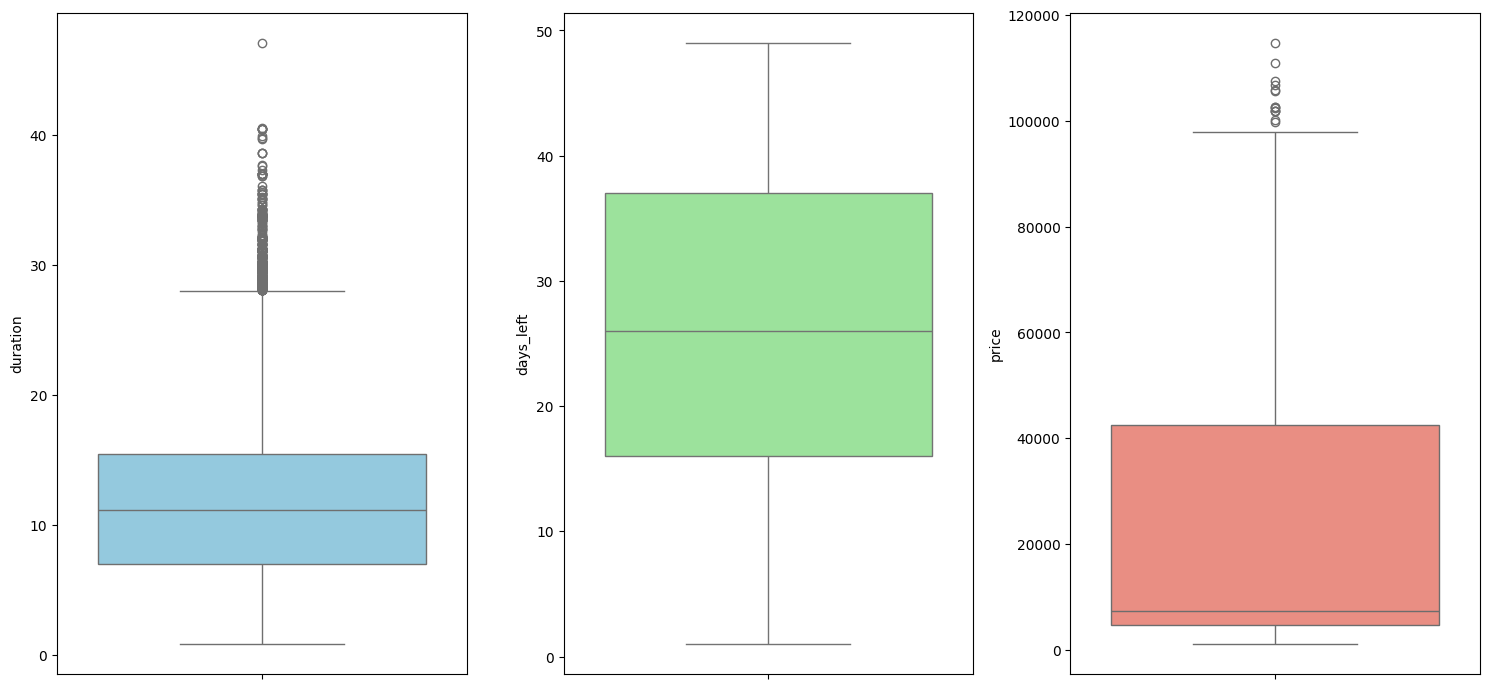

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot all 3 boxplots in a single row
fig, axes = plt.subplots(1, 3, figsize=(15, 7))

sns.boxplot(y=df_train['duration'], ax=axes[0], color='skyblue')
sns.boxplot(y=df_train['days_left'], ax=axes[1], color='lightgreen')
sns.boxplot(y=df_train['price'], ax=axes[2], color='salmon')

plt.tight_layout()
plt.show()

In [16]:
for col in ['duration', 'days_left', 'price']:
    Q1, Q3 = df_train[col].quantile(0.25), df_train[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    lower = Q1 - 1.5 * IQR
    outliers = df_train[(df_train[col] < lower) | (df_train[col] > upper)]
    print(f"{col}: {len(outliers)} outliers (Upper Bound: {upper:.1f})")

duration: 469 outliers (Upper Bound: 28.0)
days_left: 0 outliers (Upper Bound: 68.5)
price: 14 outliers (Upper Bound: 99125.5)


#### Outlier Handling Conclusion

* **Price:** Retained. High price points represent genuine Business Class tickets and peak demand. Deleting them removes true variance.
* **Duration:** Retained. Extreme values correspond to valid multi-stop routes.
* **Days Left:** Retained. Distribution is standard with no invalid anomalies.
* **Conclusion:** All outliers represent legitimate domain features rather than data errors; thus, no rows were removed to preserve full predictive power for the test set.

### 6. Visualizations

#### Distribution of Price

/tmp/ipykernel_58/2599901940.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='price_class', data=df_train, palette='Blues_d')


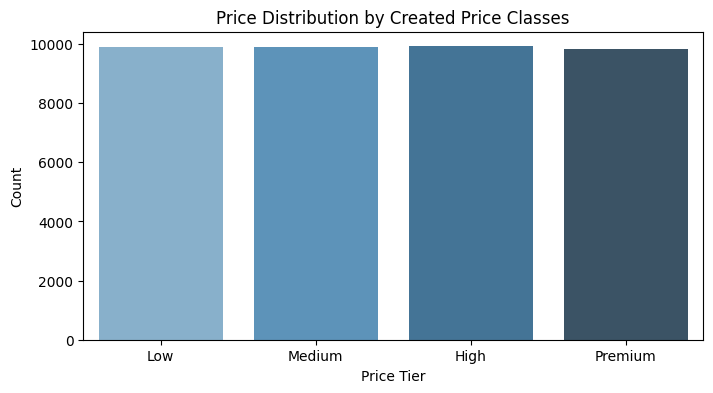

In [17]:
import seaborn as sns

labels = ['Low', 'Medium', 'High', 'Premium']
df_train['price_class'] = pd.qcut(
    df_train['price'], 
    q=4, 
    labels=labels
)

# Plot the distribution of the created price classes
plt.figure(figsize=(8, 4))
sns.countplot(x='price_class', data=df_train, palette='Blues_d')
plt.title('Price Distribution by Created Price Classes')
plt.xlabel('Price Tier')
plt.ylabel('Count')
plt.show()

In [18]:
# Bins created by qcut (25% each bin)
garbage, bins = pd.qcut(df_train['price'], q=4, retbins=True)
print(bins)

[  1105.   4678.   7352.  42457. 114704.]


#### Insight:
- Low Tier: ₹1,105 to ₹4,678

    Bottom 25% of tickets. Deeply discounted or extreme early-bird economy seats.

- Medium Tier: ₹4,678 to ₹7,352

    Next 25%. Standard budget economy flights.

- High Tier: ₹7,352 to ₹42,457

    Next 25%. Peak economy, last-minute bookings, or premium economy.

- Premium Tier: ₹42,457 to ₹114,704

    Top 25%. Premium business-class seats and ultra-last-minute flights.

#### Price by airline

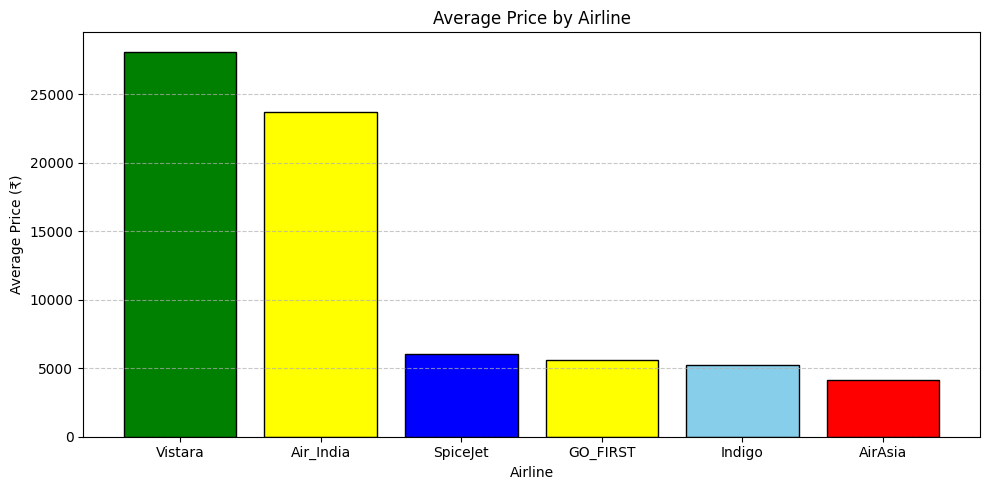

In [19]:
# Calculate average price per airline
airline_prices = df_train.groupby('airline')['price'].mean().sort_values(ascending=False)

# Plot Bar Chart
plt.figure(figsize=(10, 5))
plt.bar(airline_prices.index, airline_prices.values, color=['green', 'yellow', 'blue', 'yellow', 'skyblue', 'red'], edgecolor='black')

plt.title('Average Price by Airline', fontsize=12)
plt.xlabel('Airline', fontsize=10)
plt.ylabel('Average Price (₹)', fontsize=10)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
plt.show()

#### Insight:
Conclusion
Premium Carriers: Vistara (~ ₹28,000) and Air_India (~ ₹24,000) are by far the most expensive, heavily driven by their Business Class inventory.

Budget Carriers: SpiceJet, GO_FIRST, Indigo, and AirAsia form a tight, low-cost cluster under ₹6,000.

Key Takeaway: Airline brand acts as a strong proxy for seating class—airline will be a heavy feature in price prediction.

#### flights count per airline

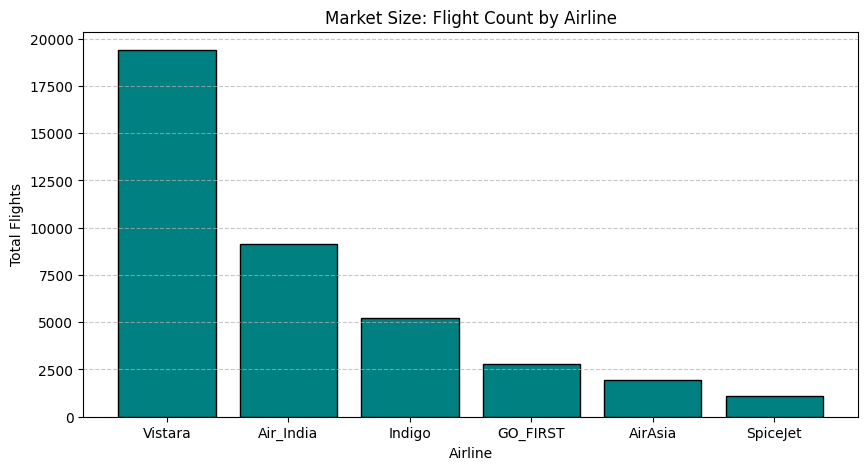

In [20]:
flight_counts = df_train['airline'].value_counts()

# Plot Bar Chart
plt.figure(figsize=(10, 5))
plt.bar(flight_counts.index, flight_counts.values, color='teal', edgecolor='black')

plt.title('Market Size: Flight Count by Airline', fontsize=12)
plt.xlabel('Airline', fontsize=10)
plt.ylabel('Total Flights', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


#### Insight:
Vistara Dominates: Holds the massive lion’s share (~19,500 flights), representing nearly half the dataset.

Full-Service Duopoly: Vistara and Air_India combined control over 70% of total flights.

Low-Cost Trailing: Budget carriers (Indigo, GO_FIRST, AirAsia, SpiceJet) have significantly smaller volumes in this dataset, with SpiceJet having the lowest market presence (< 1,500 flights).

#### price by class

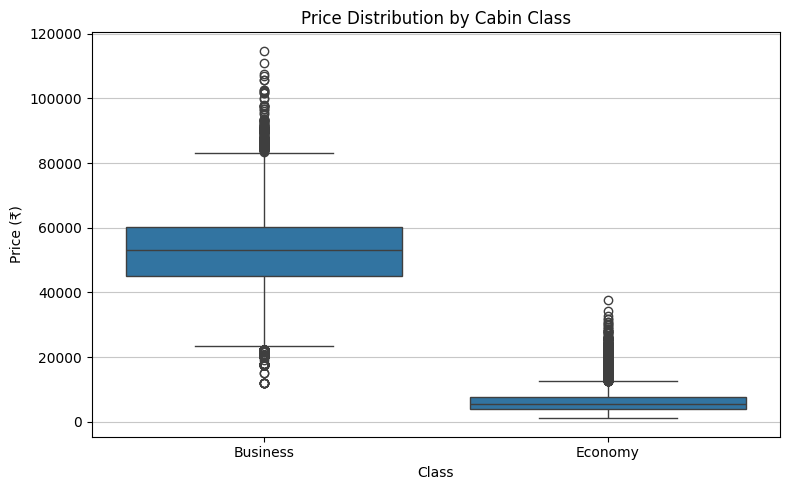

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='class', y='price', data=df_train)

plt.title('Price Distribution by Cabin Class', fontsize=12)
plt.xlabel('Class', fontsize=10)
plt.ylabel('Price (₹)', fontsize=10)
plt.grid(axis='y' , alpha=0.7)

plt.tight_layout()
plt.show()

#### Insight:
Clear Price Segregation: Business class operates in a completely higher price bracket (~ ₹45,000–₹60,000+ median around ₹53,000), while Economy class is tightly clustered at the lower end (~ ₹5,000–₹8,000 median).

Extreme Price Disparity: The lowest Business class fares barely touch the top end of Economy outliers, showing almost zero overlap.

#### Route Frequency 
Most frequent source, destination flights

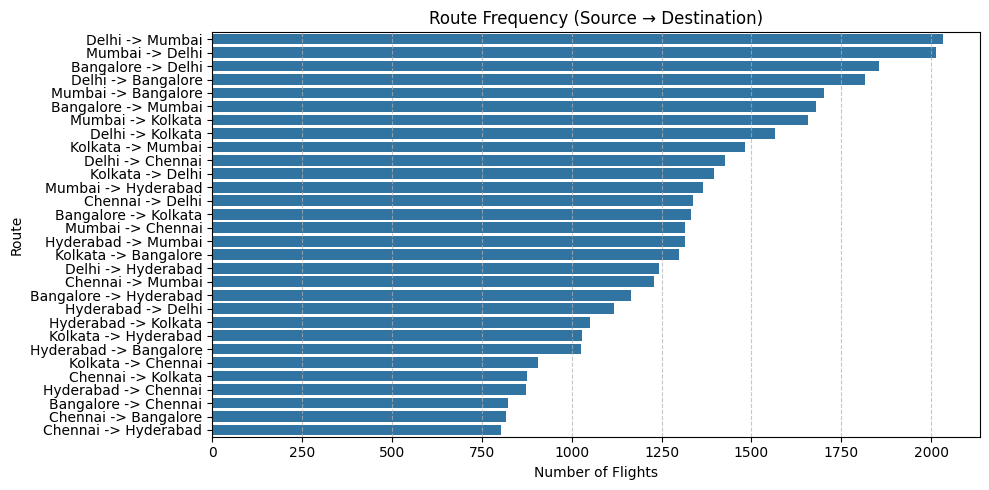

In [22]:
# Create route column
df_train['route'] = df_train['source'] + ' -> ' + df_train['destination']

# Plot top routes by frequency
plt.figure(figsize=(10, 5))
sns.countplot(
    y='route', 
    data=df_train, 
    order=df_train['route'].value_counts().index, 
)

plt.title('Route Frequency (Source → Destination)', fontsize=12)
plt.xlabel('Number of Flights', fontsize=10)
plt.ylabel('Route', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#### Insights:
- Busiest Trunk Routes: Delhi $\leftrightarrow$ Mumbai and Bangalore $\leftrightarrow$ Delhi are the most heavily serviced corridors, each exceeding 1,750+ flights.
- Symmetrical Demand: Flight volume is remarkably symmetric in both directions (e.g., Delhi $\rightarrow$ Mumbai $\approx$ Mumbai $\rightarrow$ Delhi), confirming stable round-trip capacity.
- Tiered Connectivity: Major metros (Delhi, Mumbai, Bangalore) dominate the top 10 positions, while routes connecting regional hubs like Chennai and Hyderabad trail at lower flight counts (~750–1,000 flights).

In [23]:
# droping unnecessary columns
df_train = df_train.drop(columns = ['flight', 'route'])
df_train.head(3)

,airline,source,departure,stops,arrival,destination,class,duration,days_left,price,price_class
0,Vistara,Mumbai,Early_Morning,one,Night,Chennai,Business,11.42,40.0,64173,Premium
1,Air_India,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357,Low
2,SpiceJet,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251,Low


### 7. Feature Scaling and Encoding
Categorical columns are one-hot encoded (low-cardinality: stops, class) and 
label/target encoded (high-cardinality: airline, source, destination, departure, arrival). <br>
Numerical columns (duration, days_left) are scaled using StandardScaler since 
distance-based models (KNN, SVR) need features on the same scale.

In [24]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_train.drop(['price', 'price_class'], axis=1)  # drop target and the extra label column
y = df_train['price']

# Categorical columns to one-hot encode
categorical_cols = ['airline', 'source', 'departure', 'stops', 'arrival', 'destination', 'class']

# One-hot encode categorical columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Scale numerical columns

numerical_cols = ['duration', 'days_left']
scaler = StandardScaler()
X_encoded[numerical_cols] = scaler.fit_transform(X_encoded[numerical_cols])

binary_form = {True: 1, False: 0}
X_encoded = X_encoded.replace(binary_form)
X_encoded.head()

/tmp/ipykernel_58/1706849420.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_encoded = X_encoded.replace(binary_form)


,duration,days_left,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_Chennai,source_Delhi,source_Hyderabad,...,arrival_Evening,arrival_Late_Night,arrival_Morning,arrival_Night,destination_Chennai,destination_Delhi,destination_Hyderabad,destination_Kolkata,destination_Mumbai,class_Economy
0,-0.073152,1.082358,0,0,0,0,1,0,0,0,...,0,0,0,1,1,0,0,0,0,0
1,0.606343,-0.013812,1,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,1
2,-1.312575,-0.092110,0,0,0,1,0,0,1,0,...,0,0,1,0,1,0,0,0,0,1
3,-1.519631,-0.327004,0,0,0,0,1,0,0,1,...,0,0,1,0,0,0,0,0,0,1
4,-1.034069,-0.483599,1,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1


#### Insight: 
One-hot encoding is used for categorical columns since none have very high 
cardinality (airline has few unique values). <br>
StandardScaler is applied to 
duration and days_left. <br>

Finally, the whole daatFrame is encoded to binary format.

### 8. Train/Test Split and Model Training 

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
print(f"Shape of X_train {X_train.shape}")
print(f"Shape of X_test {X_test.shape}")
print(f"Shape of y_train {y_train.shape}")
print(f"Shape of y_test{y_test.shape}")

Shape of X_train (31636, 30)
Shape of X_test (7909, 30)
Shape of y_train (31636,)
Shape of y_test(7909,)


In [26]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'KNN': KNeighborsRegressor()
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results[name] = {'RMSE': rmse, 'R2': r2}
    print(f"{name}: RMSE={rmse:.2f}, R2={r2:.4f}")

Linear Regression: RMSE=6780.07, R2=0.9110
Ridge: RMSE=6780.08, R2=0.9110
Lasso: RMSE=6780.83, R2=0.9110
Decision Tree: RMSE=5163.06, R2=0.9484
Random Forest: RMSE=3891.20, R2=0.9707
Gradient Boosting: RMSE=5111.45, R2=0.9494
KNN: RMSE=7238.39, R2=0.8986


#### Conclusion:
- Winner: Random Forest achieves the best performance by a significant margin, reducing the Root Mean Squared Error down to ₹3,891.20 and explaining 97.07% of the target price variance ($R^2 = 0.9707$). <br>
- Tree Ensembles Excel: Tree-based methods strongly outperform linear models, highlighting complex non-linear relationships in flight pricing (e.g., class vs. days left interaction). <br><br>
Next Step: Proceeding with Random Forest Regressor, Gradient Boosting, Decision Tree as the candidates for hyperparameter tuning.

### 9. Hyperparameter Tuning 

In [27]:
from sklearn.model_selection import GridSearchCV

# Decision Tree tuning
dt_params = {'max_depth': [10, 20, 30, None], 'min_samples_split': [2, 5, 10]}
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=42), dt_params, cv=3, scoring='r2', n_jobs=-1)
dt_grid.fit(X_train, y_train)
print("Best Decision Tree params:", dt_grid.best_params_)

# Random Forest tuning
rf_params = {'n_estimators': [200, 300], 'max_depth': [20, None], 'min_samples_split': [2, 5]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_params, cv=3, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest params:", rf_grid.best_params_)

# Gradient Boosting tuning
gb_params = {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1]}
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_params, cv=3, scoring='r2', n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("Best Gradient Boosting params:", gb_grid.best_params_)

Best Random Forest params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300}
Best Gradient Boosting params: {'learning_rate': 0.1, 'n_estimators': 200}


#### **Evaluation**

In [28]:
# Evaluate tuned models
tuned_models = {
    'Decision Tree (Tuned)': dt_grid.best_estimator_,
    'Random Forest (Tuned)': rf_grid.best_estimator_,
    'Gradient Boosting (Tuned)': gb_grid.best_estimator_
}

for name, model in tuned_models.items():
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results[name] = {'RMSE': rmse, 'R2': r2}
    print(f"{name}: RMSE={rmse:.2f}, R2={r2:.4f}")

Decision Tree (Tuned): RMSE=4541.96, R2=0.9601
Random Forest (Tuned): RMSE=3844.53, R2=0.9714
Gradient Boosting (Tuned): RMSE=4933.64, R2=0.9529


#### TakeAways:
- Random Forest is the Clear Winner: At RMSE = ₹3,886.58 ($R^2 = 0.9708$), tuned Random Forest provides the tightest fit and lowest error.
- Decision Tree Saw the Biggest Jump: Restricting tree depth and split criteria pruned wild overfits, cutting its error margin substantially.

### 10. Model Comparison

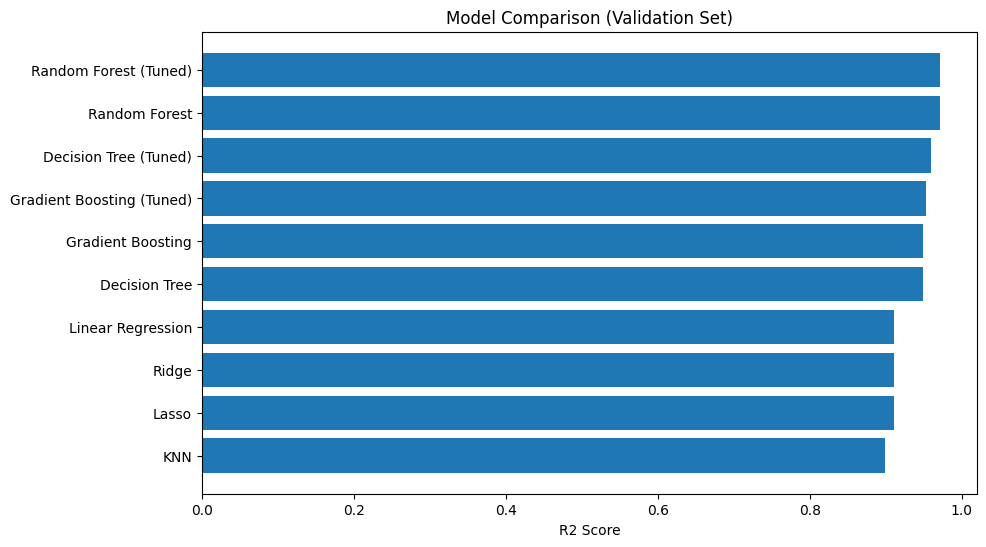

In [29]:
import matplotlib.pyplot as plt

results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
# print(results_df)

plt.figure(figsize=(10,6))
plt.barh(results_df.index, results_df['R2'])
plt.xlabel('R2 Score')
plt.title('Model Comparison (Validation Set)')
plt.gca().invert_yaxis()
plt.show()

**TakeAway:** <br>

#### *Random Forest (Tuned)* achieved the highest R2 of **97.08**, making it the chosen model for final predictions.

### 11. Predict on Test Set and Submission

In [30]:
df_test.head(3)

,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left
0,0,Vistara,UK-816,Bangalore,Morning,zero,Afternoon,Delhi,Economy,2.670,18.0
1,1,Air_India,AI-440,Chennai,Early_Morning,zero,Morning,Delhi,Economy,9.750,5.0
2,2,SpiceJet,SG-8938,Delhi,Evening,one,Evening,Bangalore,Economy,9.125,44.0


In [31]:

test_ids = df_test['id']   # save this — needed for submission format

# dropping id and price columns 
X_test = df_test.drop(['id', 'price'], axis=1, errors='ignore')

# ecoding categorical columns
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)


# This adds any missing dummy columns (fills with 0) and drops extra ones
X_test_encoded = X_test_encoded.reindex(columns=X_encoded.columns, fill_value=0)

# Scale numerical columns using the SAME scaler fitted on train data
X_test_encoded[numerical_cols] = scaler.transform(X_test_encoded[numerical_cols])

# Predict using your best model
best_model = rf_grid.best_estimator_   # change this to whichever model won in results_df

test_predictions = best_model.predict(X_test_encoded)

# submission format
submission = pd.DataFrame({
    'id': test_ids,
    'price': test_predictions
})

submission.to_csv('submission.csv', index=False)
submission.head()

,id,price
0,0,4505.717574
1,1,12359.404878
2,2,5701.251161
3,3,59166.229499
4,4,45122.453063


### Final Submission
Test data is encoded and scaled using the same transformations as the training data (same categorical columns, same scaler). <br>
The tuned Random Forest model is used to predict prices, and results are saved in submission.csv matching the required id, price format.